# Cow Behaviour Classification

*Practical: monitoring accelerometer data*

## Introduction

In this notebook we predict cow behaviour from **RumiWatch** sensor data. The data contain movement and pressure measurements from **three dairy cows**. We train the models on two cows and test them on a third cow that the model has never seen. This is important: a model that works for the cows it was trained on does not automatically work for a new animal, and a new animal is what we face in practice.

Main learning points:
- **Evaluation by animal.** Windows of the same animal are very similar. A model must be validated and tested on animals that it did not see during training.
- **Data leakage.** Information from validation or test data can leak into the model in many hidden ways. Pipelines and a correct cross-validation prevent this.
- **Overfitting and model choice.** Tools such as cross-validation by animal, validation curves and tuning grids help to choose features and settings without looking at the test cow.
- **Imbalanced classes.** Behaviours are not equally common, so accuracy alone is misleading.
- **A usable model.** At the end you save a complete model that turns raw sensor data into behaviours, and test it once on the new cow.


### Official documentation

When you are unsure about a function, start with the official documentation.

| Library | Where to look |
|---------|----------------|
| **scikit-learn** | [User guide](https://scikit-learn.org/stable/user_guide.html), [API reference](https://scikit-learn.org/stable/api/index.html), [Common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html) |
| **XGBoost** | [Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html) |
| **pandas** | [User guide](https://pandas.pydata.org/docs/user_guide/index.html) |
| **matplotlib** | [Tutorials](https://matplotlib.org/stable/tutorials/index.html) |

## Table of contents

1. **Setup**: load the sensor data
2. **Train-test split by cow** (before looking at the data)
3. **Data exploration of the training cows**: summary, class distribution, raw signals with behaviour labels, measuring the chewing rhythm
4. **Feature engineering**: windows, your own feature, purity, features per behaviour
5. **Baseline classifier**
6. **Random Forest pipeline**: first look at the test cow
7. **Data leakage and cross-validation by cow**
8. **A feature from biology**: the chewing rhythm
9. **Overfitting and tuning**: validation curve, tuning grid, XGBoost
10. **Threshold**: ROC and precision-recall curves, Youden index, confusion matrix
11. **Save the complete model**
12. **Final test on the new cow**
13. **Extra challenges**
14. **Validation plan** for a new sensor (half a page)

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:12px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<b>How this notebook works</b>
<ul>
<li>Run the cells from top to bottom with <b>Shift + Enter</b>.</li>
<li><span style="background:#E3F2FD;border-left:4px solid #1976D2;padding:1px 8px">Blue boxes</span> are tasks. Write your code in the cell below the task, between <code>YOUR CODE STARTS HERE</code> and <code>YOUR CODE ENDS HERE</code>, and use the variable names of the task: later cells need them.</li>
<li><span style="background:#F5F5F5;border-left:4px solid #9E9E9E;padding:1px 8px">Grey boxes</span> contain hints (click to open) or background.</li>
<li><b>Your answer</b> cells: write your answer in a few sentences.</li>
<li><b>Check cells</b> list what they check and why. Green means that your result has the right form, not that your model is good.</li>
</ul>
</div>

### About the sensor

The animation below shows a cow with the RumiWatch sensor next to the live pressure signal of the sensor (top right). The regular pattern in this signal comes from the jaw movements of the cow. The sensor also records head movement with an accelerometer (x, y and z axes) and the temperature.

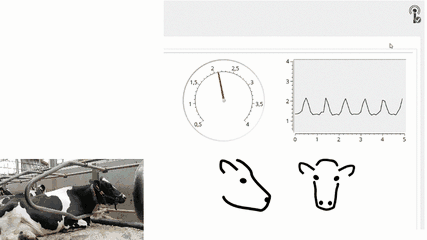

Different behaviours give different sensor patterns. In this practical you teach a model to recognise them.

## 1. Setup

### 1.1 Project set-up



In [ ]:
import subprocess
import sys
from pathlib import Path

# Project root = folder containing functions/ (works when the working directory is the project root or notebooks_code/)
project_root = Path.cwd()
if not (project_root / "functions").exists():
    project_root = project_root.parent

### 1.2 Import required libraries

Import the libraries for data processing, model training and visualization, and the helper tools of this practical.

In [ ]:
import pickle
import warnings
import zipfile

import cloudpickle
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    LeaveOneGroupOut,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# Hide a harmless warning that scikit-learn sometimes repeats thousands of times when models run in parallel
warnings.filterwarnings("ignore", message=r".*sklearn\.utils\.parallel\.delayed.*", category=UserWarning)

# Helper tools of this practical (technical checks of your results and a few tools)
sys.path.append(str(project_root / "functions"))
from practical_tools import (
    check_extra_features,
    check_grid_search,
    check_pipeline,
    check_predictions,
    check_saved_model,
    check_train_test_split,
)

### 1.3 Load data

The practical uses data from **three dairy cows** (`275a`, `655a` and `638b`), each equipped with a RumiWatch sensor. For every cow there are 2 to 3 weeks of raw sensor measurements and behaviour labels, in total more than 40 million rows. To limit the memory use, we only load the columns that we need (`time`, `pressure`, `move_x`, `move_y`, `move_z` and `classification`) with compact data types. The cows are first stored separately in the dictionary `cows`.

In [ ]:
cow_ids = ["275a", "655a", "638b"]

# Only load the columns that we need, with compact data types
column_types = {
    "time": "str",
    "pressure": "float32",
    "move_x": "float32",
    "move_y": "float32",
    "move_z": "float32",
    "classification": "int8",
}

cows = {}
for cow_id in cow_ids:
    zip_path = project_root / "data" / "raw" / f"rwu_{cow_id}_1.zip"
    with zipfile.ZipFile(zip_path, "r") as z:
        with z.open(f"rwu_{cow_id}_1.csv") as f:
            cow_df = pd.read_csv(f, sep=";", usecols=list(column_types), dtype=column_types)
    cow_df["time"] = pd.to_datetime(cow_df["time"], format="%d.%m.%Y %H:%M:%S.%f")
    cows[cow_id] = cow_df
    print(f"Cow {cow_id}: {len(cow_df):,} rows, from {cow_df['time'].iloc[0]} to {cow_df['time'].iloc[-1]}")

print(cows[cow_ids[0]].head())

### 1.4 Estimate the sampling frequency

Before we use time windows, it is useful to check the sampling frequency from the data itself, and not only rely on the documentation of the sensor. The `time` column contains measurements every 0.1 seconds, which corresponds to 10 measurements per second.

The code below estimates this frequency for every cow from the median time difference between consecutive rows. We use the median because it is robust to an occasional irregular time stamp, for example when the clock changes between summer and winter time.

In [ ]:
# Estimate the sampling frequency per cow from the timestamp column.
sampling_rates = {}
for cow_id, cow_df in cows.items():
    time_step_seconds = cow_df["time"].diff().dt.total_seconds().median()
    sampling_rates[cow_id] = int(round(1 / time_step_seconds))
    print(f"Cow {cow_id}: time step {time_step_seconds:.3f} seconds = {sampling_rates[cow_id]} Hz")

assert len(set(sampling_rates.values())) == 1, "All cows should have the same sampling frequency"
sampling_rate_hz = sampling_rates[cow_ids[0]]

### 1.5 Drop habituation period

To avoid unreliable sensor data during habituation, the first 2 hours of measurements of every cow are dropped. We use the estimated sampling frequency to calculate how many rows correspond to 2 hours.

In [ ]:
# Drop first 2 hours of data of every cow.
habituation_rows = 2 * 60 * 60 * sampling_rate_hz
cows = {cow_id: cow_df.iloc[habituation_rows:] for cow_id, cow_df in cows.items()}

### 1.6 Combine the cows

All cows are combined in one DataFrame `df_data` with the extra column `cow_id`. We use this column later to split the data by animal. The features in section 4 are calculated for every cow separately, so that a window never contains measurements of two cows.

In [ ]:
df_data = pd.concat(cows, names=["cow_id", None]).reset_index(level="cow_id")
df_data = df_data.reset_index(drop=True)
df_data["cow_id"] = df_data["cow_id"].astype("category")

del cows, cow_df  # free memory
print(f"All cows together: {df_data.shape[0]:,} rows")
print(df_data["cow_id"].value_counts().sort_index())

## 2. Train-test split by cow

We train on two cows and test on a third cow, a **new animal** for the model. In practice a model is always applied to animals it has not seen. A random split of windows, or a split in time within one cow, is too optimistic: neighbouring windows of one cow are very similar, and the model learns the typical signals of that cow.

We split **before** exploring the data. What you see influences your choices (features, window length, merging behaviours); if you look at the test cow while making them, the final test is no longer independent. This is data leakage through the analyst. The test cow is therefore only used to evaluate: a first look in sections 5 and 6, and the final test in section 12.

In [ ]:
train_cows = ["275a", "655a"]
test_cow = "638b"

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**2.1 — TASK**

Split `df_data` into a training set and a test set. Assign them to `train` and `test`.

- `train` contains **all** rows of the cows in `train_cows`.
- `test` contains **all** rows of the cow `test_cow`.
- Keep all columns of `df_data`.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li>Use the column <code>cow_id</code> with a boolean mask: <code>df_data["cow_id"].isin(train_cows)</code> for the training cows and <code>df_data["cow_id"] == test_cow</code> for the test cow.</li><li>Add <code>.copy()</code>, so that later changes to <code>train</code> do not affect <code>df_data</code>.</li><li>Do not shuffle or sample rows: take all rows of the cows.</li><li>Keep all columns. You need <code>time</code> later for the plots.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

In [ ]:
# Technical check of your result: the output lists every check and why it matters
check_train_test_split(train, test, df_data, train_cows, test_cow)

## 3. Data exploration (training cows only)

### Overview of the variables

| Variable       | Description                                  |
|----------------|----------------------------------------------|
| time           | Logging date and time (DD.MM.YYYY, hh:mm:ss) |
| pressure       | Pressure value of the noseband sensor        |
| move_x         | Acceleration in x-axis                       |
| move_y         | Acceleration in y-axis                       |
| move_z         | Acceleration in z-axis                       |
| classification | Behaviour label of the measurement           |
| cow_id         | Cow (added in section 1.6)                   |

The original files also contain `temperature` and `peak_time` (an internal counter of the sensor); these are not loaded.

**Classification mapping:**

| Label | Meaning        |
|-------|----------------|
| 0     | Other activity |
| 1     | Rumination     |
| 2     | Feed intake    |
| 4     | Water intake   |

The goal is to predict the `classification` label from the sensor measurements. We treat this column as the **reference label**: the label against which our predictions are compared. The data do not show whether these labels come from human observation, video annotation or the RumiWatch software itself. In a real study, the origin and reliability of the reference labels must be checked carefully.

All tasks in this section use `train` only.

### 3.1 Summary of the training data

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**3.1 — TASK**

Make a summary of the training data. Then compare the two training cows: do their sensor values have a similar scale and spread?

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li>Use <code>train.describe()</code> or similar pandas summary methods.</li><li>Check row counts, ranges of sensor columns, and missing values.</li><li>To compare the cows, group by the cow: <code>train.groupby("cow_id", observed=True)[[...]].agg([...])</code> with for example the mean and standard deviation.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Do the two training cows have a similar scale and spread of the sensor values? Which sensor differs most between the cows?
- Why could this matter for a model that is trained on these cows and applied to a new cow?

---

> *Write your answer here...*

### 3.2 Class distributions

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**3.2 — TASK**

Visualize the class distribution for each training cow separately. Which class is the majority class? Are the cows similar?

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li>Use <code>pd.crosstab(train["cow_id"], train["classification"], normalize="index")</code> to get the share of every class per cow.</li><li>Plot the table as a grouped bar chart (<code>.plot(kind="bar")</code>).</li><li>Label axes and title clearly. Note which class is the majority class: this matters for the baseline later.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Which class is the majority class? How large is the smallest class?
- What accuracy would a model get that always predicts the majority class?

---

> *Write your answer here...*

### 3.3 Merge ingestive classes

Water intake is very rare, and a drinking bout usually lasts shorter than the windows of 60 seconds that we use in section 4. For this exercise we therefore combine class 4 (water intake) with class 2 (feed intake) as "ingestive behaviour", in the training and in the test data.

In [ ]:
# Add class 4 (water intake) to class 2 (feed intake)
train["classification"] = train["classification"].replace(4, 2)
test["classification"] = test["classification"].replace(4, 2)

### 3.4 Behaviour labels and colours

To make the output easier to read, we map the class numbers to behaviour names. We also fix one colour per behaviour and use it in all plots of this notebook. The colours come from a palette that is also readable for people with colour vision deficiency.

In [ ]:
# Map class numbers to behaviour labels
class_mapping = {
    0: "Other activity",
    1: "Rumination",
    2: "Ingestive behaviour",
}

# One colour per behaviour, used in all plots
behaviour_colours = {
    0: "#999999",  # grey
    1: "#009E73",  # green
    2: "#E69F00",  # orange
}

# Add readable behaviour column
for part in (train, test):
    part["behaviour"] = part["classification"].map(class_mapping).astype("category")

# Quick check
print(train[["classification", "behaviour"]].drop_duplicates().sort_values("classification"))

### 3.5 Raw sensor data and behaviour labels

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**3.5 — TASK**

Plot **one hour** of raw sensor data of cow `275a`, from **8 September 2019 14:00 to 15:00**, together with the behaviour labels. In this hour all three behaviours occur.

- Show `pressure` and the three acceleration axes (`move_x`, `move_y`, `move_z`) over time. Two panels above each other with a shared time axis are easier to read than one panel with four lines.
- Show the behaviour labels as coloured background bands, with the colours of `behaviour_colours`.
- The legend must explain the background colours with the class number **and** the behaviour name, for example `1 = Rumination`.
- Choose line colours that differ clearly from the background colours.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li>Select the cow and the hour: <code>cow_data = train[train["cow_id"] == "275a"]</code>, then <code>cow_data[(cow_data["time"] >= start) & (cow_data["time"] < end)]</code> with <code>start = pd.Timestamp("2019-09-08 14:00")</code>.</li><li>Two panels: <code>fig, (ax_pressure, ax_move) = plt.subplots(2, 1, sharex=True)</code>.</li><li>Background bands: <code>ax.fill_between(time, 0, 1, where=(classification == class_code), color=..., alpha=0.3, transform=ax.get_xaxis_transform())</code>. With this <code>transform</code>, 0 and 1 mean the bottom and the top of the panel.</li><li>A legend for the bands: make handles with <code>Patch(facecolor=colour, alpha=0.3, label=f"{class_code} = {name}")</code> and pass them with <code>ax.legend(handles=...)</code>.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Describe how the pressure signal looks during rumination, during ingestive behaviour and during other activity.
- Which signal (pressure or acceleration) do you expect to be most useful to recognise each behaviour?
- Do the label changes look plausible when you look at the signals?

---

> *Write your answer here...*

### 3.6 Measure the chewing rhythm

Rumination and ingestive behaviour both consist of jaw movements, and both give many pressure peaks. To tell them apart, it helps to know how they differ in **rhythm**. In this task you measure that yourself, by looking at the signal. You will use your measurements to design your own feature (task 4.1 and section 8).

During rumination, the cow regurgitates a bolus of feed from the rumen, chews it for a while, swallows it, and regurgitates the next one. A short pause in the chewing marks the change to the next bolus.

Everybody inspects the same two minutes of cow 275a, given in the cell below, so that you can compare your counts with each other.

In [ ]:
# The two minutes to inspect (cow 275a, 8 September 2019), the same for everybody
rumination_start = pd.Timestamp("2019-09-08 14:19:07.8")
ingestive_start = pd.Timestamp("2019-09-08 14:47:17.8")
one_minute = 60 * sampling_rate_hz  # 600 measurements

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**3.6 — TASK**

1. Plot the pressure of the **minute of rumination** (600 measurements from `rumination_start`) and the **minute of ingestive behaviour** (600 measurements from `ingestive_start`) of cow 275a, above each other, with a time axis in seconds.
2. **Count** the chewing cycles (pressure peaks) in each minute by looking at your plot. Report the number of cycles per minute for both behaviours.
3. In the plot of task 3.5, measure the **duration of one bolus cycle** during rumination: the time from one chewing pause to the next. Measure several cycles and report the mean.
4. Describe in words how the rhythm differs between the two behaviours (rate, regularity, pauses).

Write down your counts and measurements in the answer box: you need them in task 4.1 and section 8.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li>Select the minute: <code>cow_data = train[train["cow_id"] == "275a"]</code> and <code>cow_data[cow_data["time"] >= rumination_start].iloc[:one_minute]</code>.</li><li>A time axis in seconds: <code>(segment["time"] - segment["time"].iloc[0]).dt.total_seconds()</code>.</li><li>Make the plot wide enough (e.g. <code>figsize=(16, 6)</code>) and add a grid every 5 seconds, so you can count the peaks per 5 seconds and add them up.</li><li>For the bolus cycle: zoom the plot of 3.5 to the rumination period of about 14:18 to 14:41, count the pauses and divide the duration by the number of cycles.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Number of chewing cycles per minute during rumination and during ingestive behaviour (your counts).
- Mean duration of a bolus cycle during rumination, and how you measured it.
- How does the rhythm differ between the two behaviours? How long is a bolus cycle compared with the window length of 60 seconds used in section 4?

---

> *Write your answer here...*

## 4. Feature engineering: windows and features

A model cannot learn much from one single measurement of 0.1 second. Behaviours such as rumination consist of patterns over many seconds (jaw movements, head movements). Therefore we cut the raw sensor data in **windows of 60 seconds** (600 measurements) and calculate **features** per window: numbers that describe the signal in the window, such as the mean or the variation. Every window becomes one row of the feature table `X`, and the behaviour of the window becomes one label in `y`.

### Derived movement features

Signal Vector Magnitude (SVM): $\sqrt{x^2 + y^2 + z^2}$, the strength of the acceleration, regardless of the direction.

Signal Magnitude Area (SMA): $|\bar{x}| + |\bar{y}| + |\bar{z}|$, the total acceleration over the three axes.

Overall Dynamic Body Acceleration (ODBA): a proxy for the activity level,

$$\mathrm{ODBA} = |a_x - \mu_x| + |a_y - \mu_y| + |a_z - \mu_z|$$

where $a_x, a_y, a_z$ are the measured accelerations and $\mu_x, \mu_y, \mu_z$ their smoothed, slowly changing part (mainly the position of the head relative to gravity). What remains is the movement.

### Window label and purity

A window of 60 seconds can contain more than one behaviour, for example when the cow stops eating and starts ruminating. The window gets the **most frequent label** of its 600 measurements. The **purity** tells how clear this label is: it is the share of the 600 measurements that have the window label.

- purity = 1.0: the whole window is one behaviour.
- purity = 0.6: 60% of the measurements have the window label and 40% another behaviour. The window contains a change of behaviour, and the label is less reliable.

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:12px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">

**Overview of the window features**

The function `extract_window_features` below calculates these 6 features for every window of 60 seconds (600 measurements). In task 4.1 you add your own feature.

| Feature | Calculation per window | What it describes |
|---------|------------------------|-------------------|
| `mean_pressure` | mean of `pressure` | average pressure level (for example how tight the sensor sits) |
| `range_pressure` | maximum minus minimum of `pressure` | size of the pressure changes, caused by jaw movements |
| `odba` | mean of the dynamic body acceleration | amount of movement of the animal |
| `svm` | mean of the signal vector magnitude $\sqrt{x^2+y^2+z^2}$ | overall strength of the acceleration |
| `svm_std` | standard deviation of the signal vector magnitude | how much the movement strength varies inside the window |
| `sma` | sum of the mean absolute values of x, y and z | total acceleration over the three axes |

**Questions to think about**
- What makes a good feature? It should differ between the behaviour classes (task 4.2), it should add information that the other features do not have yet, it should be cheap to calculate, and it must be available when you apply the model to new data.
- The window length (60 seconds) is a choice. A short window follows quick changes but contains few jaw movements. A long window is more stable but mixes behaviours more often (lower purity).

</div>

In [ ]:
def compute_odba_xyz(ax, ay, az, alpha=0.10):
    """
    Mean ODBA of tri-axial accelerometer data (for example one window).

    The static part of every axis is estimated with an exponential moving average (EMA);
    ODBA is the sum of the absolute deviations from it.

    Parameters
    ----------
    ax, ay, az : array-like
        Acceleration measurements along x, y, z axes.
    alpha : float, default=0.10
        EMA smoothing factor.

    Returns
    -------
    mean_odba : float
        Mean ODBA over the measurements.
    """

    ax = np.asarray(ax, dtype=float)
    ay = np.asarray(ay, dtype=float)
    az = np.asarray(az, dtype=float)

    if not (len(ax) == len(ay) == len(az)):
        raise ValueError("ax, ay, and az must have the same length")

    def ema(x):
        # Exponential moving average: mu[0] = x[0] and mu[i] = alpha * x[i] + (1 - alpha) * mu[i - 1]
        return pd.Series(x).ewm(alpha=alpha, adjust=False).mean().to_numpy()

    sx = ema(ax)
    sy = ema(ay)
    sz = ema(az)

    dx = ax - sx
    dy = ay - sy
    dz = az - sz

    odba = np.abs(dx) + np.abs(dy) + np.abs(dz)
    mean_odba = float(np.mean(odba))

    return mean_odba

In [ ]:
def extract_window_features(
    df,
    n_seconds=60,
    sampling_rate=sampling_rate_hz,
    label_col="classification",
):
    """Cut the data of ONE cow in windows and calculate the features per window.

    Returns
    -------
    features : DataFrame, one row per window
    labels : Series with the most frequent label per window (None if the data have no labels)
    windows : DataFrame with the start time and the purity of every window
    """
    window_size = n_seconds * sampling_rate
    n_windows = len(df) // window_size  # the last incomplete window is dropped
    has_labels = label_col in df.columns

    features = []
    labels = []
    window_info = []

    for i in range(n_windows):
        window = df.iloc[i * window_size:(i + 1) * window_size]

        # Pressure features
        mean_pressure = np.mean(window["pressure"])
        range_pressure = np.max(window["pressure"]) - np.min(window["pressure"])

        # Accelerometer features
        acc_mag = np.sqrt(window["move_x"]**2 + window["move_y"]**2 + window["move_z"]**2)
        mean_odba = compute_odba_xyz(window["move_x"], window["move_y"], window["move_z"], alpha=0.15)
        svm = np.mean(acc_mag)
        svm_std = np.std(acc_mag)
        sma = (
            np.abs(window["move_x"]).mean()
            + np.abs(window["move_y"]).mean()
            + np.abs(window["move_z"]).mean()
        )

        window_features = {
            "mean_pressure": mean_pressure,
            "range_pressure": range_pressure,
            "odba": mean_odba,
            "svm": svm,
            "svm_std": svm_std,
            "sma": sma,
        }

        # ---------- YOUR FEATURE (task 4.1) ----------
        # Add one or a few lines that calculate your own feature from `window`, for example:
        # window_features["my_feature"] = ...
        # ---------------------------------------------
        features.append(window_features)

        # Window label = most frequent label; purity = share of measurements with that label
        purity = np.nan
        if has_labels:
            label_distribution = window[label_col].value_counts(normalize=True)
            labels.append(label_distribution.index[0])
            purity = label_distribution.iloc[0]
        window_info.append({"window_start": window["time"].iloc[0], "purity": purity})

    labels = pd.Series(labels, name=label_col) if has_labels else None
    return pd.DataFrame(features), labels, pd.DataFrame(window_info)

### 4.1 Your own feature

In tasks 3.5 and 3.6 you looked at the raw signals and measured the chewing rhythm. Now you turn an observation into a feature: a number per window that should differ between behaviours.

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**4.1 — TASK**

Add your feature as a line (or a few lines) to the function `extract_window_features` in the cell above, at the place marked `YOUR FEATURE`. Give it a clear name, for example `window_features["pressure_peaks"] = ...`. Then run the cell again, and continue with the next cells: the features are calculated with your feature included.

Answer the questions in the answer cell below **before** you write the code.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li><code>window</code> is a DataFrame with the 600 measurements of one window; <code>window["pressure"].to_numpy()</code> gives the pressure as an array.</li><li>Ideas: the number of pressure peaks (a measurement that is higher than both neighbours and higher than the mean of the window), the share of time with almost no pressure change (pauses), the standard deviation of the head position (<code>move_z</code>).</li><li>Your feature must only use the sensor columns of the window, never the label (<code>classification</code>): new data have no labels.</li><li>Check after running the cells below that <code>X_train</code> has an extra column with your feature.</li></ul>
</details>
</div>

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Which difference between behaviours did you see in tasks 3.5 and 3.6 that the existing features do not describe yet?
- Give your definition of the feature in words or as a formula.
- Which values do you expect for rumination, ingestive behaviour and other activity?

---

> *Write your answer here...*

The function `extract_window_features` works on the data of **one cow**. The helper `cow_frames` splits a DataFrame in one DataFrame per cow, and `extract_features_per_cow` calculates the windows for every cow separately and stacks them. In this way, a window never contains measurements of two cows. The table `windows_train` keeps the cow, the start time and the purity of every window. We apply it to the training and test sets (this takes a few minutes).

In [ ]:
def cow_frames(df):
    """Return the data of every cow in `df` as a separate DataFrame."""
    return [cow_df for _, cow_df in df.groupby("cow_id", sort=False, observed=True)]


def extract_features_per_cow(df, **kwargs):
    """Calculate the window features for every cow separately and stack the results."""
    X_parts, y_parts, window_parts = [], [], []
    for cow_df in cow_frames(df):
        X_cow, y_cow, windows_cow = extract_window_features(cow_df, **kwargs)
        windows_cow["cow_id"] = str(cow_df["cow_id"].iloc[0])
        X_parts.append(X_cow)
        y_parts.append(y_cow)
        window_parts.append(windows_cow)
    X = pd.concat(X_parts, ignore_index=True)
    y = pd.concat(y_parts, ignore_index=True)
    windows = pd.concat(window_parts, ignore_index=True)
    return X, y, windows

In [ ]:
X_train, y_train, windows_train = extract_features_per_cow(train)
X_test, y_test, windows_test = extract_features_per_cow(test)

print(f"Train shape {X_train.shape}, Test shape {X_test.shape}")
print("Windows per training cow:")
print(windows_train["cow_id"].value_counts())

### Purity of the windows

The code below shows how pure the windows are, per behaviour.

In [ ]:
purity_table = windows_train.assign(behaviour=y_train.map(class_mapping)).groupby("behaviour")["purity"]
display(pd.DataFrame({
    "number of windows": purity_table.size(),
    "mean purity": purity_table.mean().round(3),
    "share of pure windows (purity = 1)": purity_table.apply(lambda p: (p == 1).mean()).round(3),
    "share of windows with purity < 0.8": purity_table.apply(lambda p: (p < 0.8).mean()).round(3),
}))

fig, ax = plt.subplots(figsize=(8, 4))
for class_code, name in class_mapping.items():
    ax.hist(windows_train.loc[y_train == class_code, "purity"], bins=np.linspace(0.3, 1, 29),
            alpha=0.6, color=behaviour_colours[class_code], label=f"{class_code} = {name}")
ax.set_xlabel("Purity of the window (share of measurements with the window label)")
ax.set_ylabel("Number of windows")
ax.set_yscale("log")
ax.legend(title="Window label")
plt.tight_layout()
plt.show()

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Which behaviour has the least pure windows? Why could that be?
- Would you remove windows with a low purity from the training data? And from the test data? Think about what happens when the model is used on a farm.

---

> *Write your answer here...*

### 4.2 Features per behaviour

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**4.2 — TASK**

Make a **violin plot** of every feature per behaviour (training windows), including your own feature. Use the **behaviour names** on the x-axis (not 0, 1, 2) and the colours of `behaviour_colours`.

A violin plot shows the whole distribution of the values: the wider the violin, the more windows have that value. Which features differ clearly between the behaviours? Does your own feature behave as you expected?

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li>Loop over <code>X_train.columns</code> and make one panel per feature: <code>fig, axes = plt.subplots(2, 4)</code> and <code>axes.ravel()</code>.</li><li>Values of one feature for one behaviour: <code>X_train.loc[y_train == class_code, feature]</code>.</li><li><code>parts = ax.violinplot(list_of_arrays, showmedians=True)</code> returns a dictionary; colour every violin with <code>body.set_facecolor(...)</code> for the bodies in <code>parts["bodies"]</code>.</li><li>A few extreme values can squeeze the violins: leave out the 1% lowest and highest values of each feature (<code>X_train[feature].quantile([0.01, 0.99])</code>).</li><li>Behaviour names on the x-axis: <code>ax.set_xticks([1, 2, 3], [class_mapping[c] for c in class_mapping], rotation=20)</code>.</li><li>Features that overlap strongly between behaviours are hard to use on their own.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Which features separate rumination from the other behaviours? Which features separate ingestive behaviour?
- Does your own feature separate the behaviours as you expected in task 4.1? If not, why not?
- Is there a single feature that separates all three behaviours? What does that mean for the model?

---

> *Write your answer here...*

## 5. Baseline model

Before training a real classifier, we make a very simple reference model. This is called a **baseline**. A baseline tells us what score we can get with almost no learning.

Here we use a **majority class baseline**. This model first looks at `y_train`, the behaviour labels in the training set. It finds the class that occurs most often. Then it predicts that same class for every row in the test set.

Important: this baseline does **not** use the sensor features in `X_train` or `X_test`. It ignores movement and pressure completely. That is why it is useful: any real model should perform better than this very simple rule.

### Reading classification metrics

We read a multiclass report **one class at a time**, as a yes/no question, for example "rumination or not?":

| Term | Meaning for one class |
|------|------------------------|
| **True positive (TP)** | belongs to the class and is predicted as the class |
| **False positive (FP)** | does not belong to the class but is predicted as the class (false alarm) |
| **False negative (FN)** | belongs to the class but is predicted as another class (missed) |
| **True negative (TN)** | does not belong to the class and is not predicted as the class |

| Metric | Formula | Question |
|--------|---------|----------|
| **Accuracy** | (TP + TN) / all windows | How many windows are correct? Misleading when one class is large. |
| **Precision** | TP / (TP + FP) | When the model predicts this class, how often is it right? |
| **Recall** | TP / (TP + FN) | Of all windows of this class, how many are found? |
| **F1-score** | 2 · precision · recall / (precision + recall) | High only when both precision and recall are high. |
| **Macro-F1** | mean of the F1-scores of the classes | Every class counts equally, also the small ones. |
| **Weighted-F1** | mean of the F1-scores, weighted by class size | Large classes count more; close to accuracy. |
| **Support** | TP + FN | Number of true windows of the class. |

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**5.1 — TASK**

Build the majority class baseline.

Use `y_train` to find the most common behaviour class in the training data. Then create predictions for the test set by predicting this same class for every test window.

Your prediction vector should have the same length as `y_test`. Store it in `y_pred_majority`. Then compare `y_pred_majority` with the true test labels `y_test` and report the accuracy.

You do not need `X_train` or `X_test` for this baseline, because the baseline ignores all sensor features.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li><code>y_train</code> contains the true behaviour labels for the training windows.</li><li>Find the most common label in <code>y_train</code> with <code>value_counts().idxmax()</code> or <code>mode()</code>.</li><li><code>y_test</code> contains the true behaviour labels for the test windows.</li><li>Create <code>y_pred_majority</code>: one prediction for each value in <code>y_test</code>, always using the majority class.</li><li>Compare <code>y_pred_majority</code> with <code>y_test</code> using <code>accuracy_score</code>.</li><li>You can also print <code>classification_report(y_test, y_pred_majority)</code> to see what happens per class.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

In [ ]:
# Technical check of your result: the output lists every check and why it matters
check_predictions(y_test, y_pred_majority, "majority class", class_mapping)

## 6. Random Forest pipeline

You train a Random Forest inside a **pipeline** and take a **first look** at the test cow.

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:12px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">

**How does a Random Forest work?**

- A **decision tree** asks a series of yes/no questions about the features, for example "is `odba` larger than 0.8?", and ends in a predicted class. A single deep tree fits the training data very well, but it is unstable: a small change in the data can give a very different tree.
- A **Random Forest** trains many trees. Each tree sees a different random sample of the training windows (bootstrap sample), and at every split only a random subset of the features is considered. The trees therefore differ. The forest predicts the class that most trees vote for, and the share of votes gives the class probabilities.
- A Random Forest does not need scaled features, because a split only compares values of one feature. We still use a `StandardScaler` here: it shows how preprocessing belongs in a pipeline, and other models (logistic regression, nearest neighbours) do need it.
- Important settings (hyperparameters): `n_estimators` (number of trees), `max_depth` and `min_samples_leaf` (limit the size of the trees and so reduce overfitting) and `max_features` (number of features considered per split). In section 9 you choose them with a tuning grid.

**What is a pipeline and why do we use it?**

A pipeline is a sequence of named steps, here `("scaler", StandardScaler())` followed by `("rf", RandomForestClassifier())`.
- `pipeline.fit(X_train, y_train)` fits the scaler on `X_train` (it learns the mean and standard deviation of every feature), transforms `X_train`, and fits the Random Forest on the scaled features.
- `pipeline.predict(X_test)` scales `X_test` with the **means and standard deviations of the training data** and then predicts.
- So the test data never influence the preprocessing. In cross-validation (section 7), every preprocessing step is likewise learned again on the training part of every fold. This prevents **data leakage**.
- One object contains all steps in the right order. That makes it easy to save and apply the model later (section 11).

</div>

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**6.1 — TASK**

Build a pipeline `rf` with a `StandardScaler` (step name `scaler`) followed by a `RandomForestClassifier` (step name `rf`). Use `n_estimators=200`, `random_state=42` and `n_jobs=-1`. Fit it on the training windows.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li><code>rf = Pipeline([("scaler", StandardScaler()), ("rf", RandomForestClassifier(...))])</code></li><li><code>random_state=42</code> makes the random choices of the forest repeatable; <code>n_jobs=-1</code> uses all processor cores.</li><li>Fit on <code>X_train</code> and <code>y_train</code> only.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

In [ ]:
# Technical check of your result: the output lists every check and why it matters
check_pipeline(rf, X_train, "Random Forest pipeline")

**Class labels and probabilities.** A classifier gives two kinds of output: `.predict(X)` gives one class per window, and `.predict_proba(X)` gives one probability per class (for a Random Forest: the share of trees that vote for the class). `.predict()` chooses the class with the highest probability. In section 10 you change this rule with a threshold.

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**6.2 — TASK**

Apply `rf` to the test windows and store the predictions in `y_pred_rf`. Report the accuracy and macro-F1, and print a classification report with the behaviour names.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li><code>y_pred_rf = rf.predict(X_test)</code></li><li><code>f1_score(y_test, y_pred_rf, average="macro")</code></li><li><code>classification_report(y_test, y_pred_rf, target_names=[class_mapping[c] for c in sorted(class_mapping)], digits=3)</code></li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

In [ ]:
# Technical check of your result: the output lists every check and why it matters
check_predictions(y_test, y_pred_rf, "random forest", class_mapping)

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- How much better is the Random Forest than the majority baseline, in accuracy and in macro-F1?
- Which behaviour is recognised worst? Look at its precision and recall: does the model predict it too often or too seldom?

---

> *Write your answer here...*

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:12px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">

**From here on, the test cow is locked away**

If we now try many features, models and settings and keep the one with the best score on the test cow, the test cow is no longer an independent test: we have chosen the model that happens to fit this cow best. The final score would be too optimistic. This is also a form of data leakage.

Therefore, from section 7 to 11, all choices are made with **cross-validation on the two training cows**. The test cow is used only once more, in section 12.

</div>

## 7. Data leakage and cross-validation by cow

**Data leakage** means that information which would not be available in practice is used while the model is trained or chosen. The model then looks better during development than it will be in practice. Some forms of leakage:

| Form of leakage | Example in this practical | Prevented by |
|---|---|---|
| The same animal in training and test data | random split of all windows | split by cow (section 2) |
| Preprocessing learned on all data | scaler fitted on training and test windows together | pipeline |
| Very similar windows in training and validation folds | random cross-validation of windows | cross-validation by cow |
| Choices made on the test set | look at the test cow while exploring, or choose features, settings or a threshold with the test cow | explore only the training cows, choose with cross-validation, test once at the end |
| Features that use the label or the future | a feature that uses the behaviour of the next window | think about what is available in practice |

### Cross-validation by cow

To compare models without the test cow, we use **cross-validation**: the training data are split in parts (folds). Each fold is used once for validation while the model is trained on the other folds. With **leave-one-group-out** cross-validation, each group (here: each cow) forms one fold. With our two training cows, this gives two folds: train on cow 275a and validate on cow 655a, and the other way around. That is exactly the situation of a new cow.

The variable `groups_train` gives the cow of every training window.

In [ ]:
groups_train = windows_train["cow_id"]
cv_by_cow = LeaveOneGroupOut()

for fold, (train_index, validation_index) in enumerate(cv_by_cow.split(X_train, y_train, groups_train), start=1):
    print(f"Fold {fold}: train on cow {groups_train.iloc[train_index].unique().tolist()}, "
          f"validate on cow {groups_train.iloc[validation_index].unique().tolist()}")

### 7.1 Random cross-validation versus cross-validation by cow

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**7.1 — TASK**

Estimate the macro-F1 of your pipeline `rf` with two kinds of cross-validation on the training windows:

1. **random** 5-fold cross-validation of the windows: `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. Store the scores in `scores_random`.
2. cross-validation **by cow**: `cv_by_cow` with `groups=groups_train`. Store the scores in `scores_by_cow`.

Compare both with the macro-F1 on the test cow of task 6.2. Which estimate is closest to the result on a new cow?

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li><code>cross_val_score(rf, X_train, y_train, cv=..., scoring="f1_macro")</code> returns one score per fold. It trains a fresh copy of the pipeline in every fold.</li><li>For cross-validation by cow, also pass <code>groups=groups_train</code>.</li><li>This cell takes about a minute: 7 Random Forests are trained.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Why is the random cross-validation so optimistic? Think about two neighbouring windows of the same cow.
- The two folds of the cross-validation by cow differ. What does this tell you about the reliability of a score that is based on one or two cows?

---

> *Write your answer here...*

## 8. A feature from biology: the chewing rhythm

The largest remaining error is the confusion between **rumination and ingestive behaviour**: both consist of jaw movements, so both give a pressure signal with many peaks. Most features describe the **size** of the movements (range, standard deviation, ODBA), not their **rhythm**. In task 3.6 you measured the rhythm yourself, and in task 4.1 you may already have made a simple rhythm feature.

Two tools from signal processing describe the rhythm per window more precisely:
- **Dominant frequency.** The Fourier transform (`np.fft.rfft`) splits a signal into sine waves of different frequencies; the power at each frequency shows how strong that rhythm is in the signal. The frequency with the highest power within a band of plausible chewing frequencies is the dominant chewing frequency. With 600 measurements at 10 Hz, the frequencies are `np.fft.rfftfreq(600, d=0.1)` (steps of 1/60 Hz).
- **Regularity (autocorrelation).** The correlation of the signal with a copy of itself, shifted by a lag. A very regular rhythm with a cycle of 0.9 s gives a high correlation at a lag of 0.9 s. The highest autocorrelation within the plausible cycle lengths measures how regular the chewing is.

**Before you write code**, answer the questions in the answer cell below. Your feature must follow from your own measurements in task 3.6, not from trial and error.

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Which property of the chewing rhythm do you expect to differ between rumination and ingestive behaviour? Use your measurements of task 3.6 (cycles per minute, regularity, pauses).
- Which values do you expect for rumination and for ingestive behaviour? Which band of frequencies (or cycle lengths) is plausible for chewing, and why?
- Why should this feature also work for a new cow, whose pressure level can be different?

---

> *Write your answer here...*

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**8.1 — TASK**

1. Write a function `rhythm_window_features(cow_df, n_seconds=60, sampling_rate=sampling_rate_hz)` that calculates at least one rhythm feature from the pressure signal for the windows of **one cow** (same windows as before). Use exactly this name: the final model in section 11 uses it.
2. Make `X_train_final` and `X_test_final`: the features of section 4 (`X_train`, `X_test`, including your own feature) plus your rhythm feature(s).
3. Make a violin plot of your feature(s) for rumination and ingestive behaviour (training windows).
4. Compare the cross-validation by cow of `rf` on `X_train` and on `X_train_final`: macro-F1 and the F1-score of ingestive behaviour per fold. Use `cross_val_predict` to get the predictions per window, so you can also count how many ingestive windows are predicted as rumination.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li>The windows are consecutive blocks of <code>window_size = n_seconds * sampling_rate</code> rows; <code>n_windows = len(cow_df) // window_size</code> (the last incomplete block is dropped) and <code>n_rows = n_windows * window_size</code>.</li><li>Cut the pressure in windows at once: <code>pressure = cow_df["pressure"].to_numpy(dtype=float)[:n_rows].reshape(n_windows, window_size)</code>, and subtract the mean of every window: <code>pressure - pressure.mean(axis=1, keepdims=True)</code>.</li><li>Dominant frequency: <code>power = np.abs(np.fft.rfft(centred, axis=1))**2</code>, <code>freqs = np.fft.rfftfreq(window_size, d=1/sampling_rate)</code>, select your band with a boolean mask and use <code>freqs[band][power[:, band].argmax(axis=1)]</code>.</li><li>Share of the power in the chewing band: <code>power[:, band].sum(axis=1) / power[:, 1:].sum(axis=1)</code> (without frequency 0).</li><li>Autocorrelation of every window at once: <code>spectrum = np.fft.rfft(centred, n=2*window_size, axis=1)</code>, <code>autocorr = np.fft.irfft(np.abs(spectrum)**2, axis=1)[:, :window_size]</code>, divide by <code>autocorr[:, :1]</code> (lag 0). The column index is the lag in measurements (index 9 = 0.9 s).</li><li><code>cross_val_predict(rf, X, y_train, cv=cv_by_cow, groups=groups_train)</code> gives one prediction per training window; compare per cow with <code>f1_score</code> and <code>confusion_matrix</code>.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

In [ ]:
# Technical check of your result: the output lists every check and why it matters
check_extra_features(X_train, X_test, X_train_final, X_test_final,
                     names=("X_train", "X_test", "X_train_final", "X_test_final"))
final_features = list(X_train_final.columns)

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Do your rhythm features differ between rumination and ingestive behaviour as you expected before you wrote the code? If not, why not?
- Do they improve the cross-validation by cow, and for which fold? How many fewer ingestive windows are predicted as rumination?
- Would you keep them in the final model? Weigh the improvement against the difference between the folds.

---

> *Write your answer here...*

## 9. Overfitting and tuning

### 9.1 Validation curve

A **validation curve** shows the training score and the validation score for different values of one hyperparameter. It is a tool to detect overfitting:
- both scores low: the model is too simple (**underfitting**);
- training score high, validation score clearly lower: the model learns details of the training cows that do not hold for a new cow (**overfitting**);
- the best setting is where the validation score is highest.

Here we vary `max_depth`, the maximum number of questions in a row in every tree.

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**9.1 — TASK**

Make a validation curve for `max_depth` in `[2, 4, 6, 8, 12, None]` of the Random Forest pipeline on `X_train_final`, with cross-validation by cow. Plot the mean training score and the mean validation score.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li><code>validation_curve(rf, X_train_final, y_train, param_name="rf__max_depth", param_range=depths, cv=cv_by_cow, groups=groups_train, scoring="f1_macro")</code> returns two arrays: training scores and validation scores, with one row per value and one column per fold.</li><li>The name <code>rf__max_depth</code> means: the parameter <code>max_depth</code> of the pipeline step <code>rf</code>.</li><li><code>None</code> (no limit) cannot be placed on a numeric axis: use the values as text labels, e.g. <code>[str(d) for d in depths]</code>.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- From which `max_depth` does the model start to overfit? How do you see this?
- Which `max_depth` would you choose, and why?

---

> *Write your answer here...*

### 9.2 Tuning grid for the Random Forest

A validation curve varies one hyperparameter. Hyperparameters interact, so in practice we search a **grid** of combinations. `GridSearchCV` trains the pipeline for every combination in every fold, and keeps the combination with the best mean validation score. With `refit=True` (the default) the best combination is then trained again on all training windows.

Points of attention:
- Use cross-validation by cow, so that the score is the score on a new cow.
- If the best value lies at the edge of your grid, the optimum may lie outside it: extend the grid.
- The number of models grows fast: 4 values × 4 values × 2 folds = 32 Random Forests. Keep the grid small.

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**9.2 — TASK**

Make a tuning grid `param_grid_rf` for the Random Forest pipeline with **at least two hyperparameters** and at least three values each (for example `max_depth` and `min_samples_leaf`). Run `GridSearchCV` with cross-validation by cow, `scoring="f1_macro"` and `return_train_score=True` on `X_train_final`. Store the fitted search in `grid_rf`.

Show the 5 best combinations with their mean training and validation scores.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li>Parameter names in a pipeline: <code>{"rf__max_depth": [...], "rf__min_samples_leaf": [...]}</code>.</li><li><code>grid_rf = GridSearchCV(rf, param_grid_rf, cv=cv_by_cow, scoring="f1_macro", return_train_score=True)</code>, then <code>grid_rf.fit(X_train_final, y_train, groups=groups_train)</code>.</li><li>Results: <code>pd.DataFrame(grid_rf.cv_results_)</code> with the columns <code>params</code>, <code>mean_train_score</code> and <code>mean_test_score</code> (here "test" means the validation cow).</li><li><code>min_samples_leaf</code> is the minimum number of windows in a leaf of a tree. Larger values give simpler trees. Try values up to about 100.</li><li>This cell takes a few minutes.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

In [ ]:
# Technical check of your result: the output lists every check and why it matters
check_grid_search(grid_rf, param_grid_rf)

### 9.3 XGBoost

**XGBoost** (extreme gradient boosting) also combines many decision trees, but in another way than a Random Forest:
- A Random Forest trains deep trees **independently** of each other and averages their votes (bagging).
- Boosting trains small trees **one after the other**. Every new tree corrects the errors of the trees before it. The `learning_rate` sets how strongly each tree corrects; a small learning rate needs more trees (`n_estimators`) but often generalises better. `max_depth` is usually small (2 to 6).

XGBoost often performs very well on tables of features, but it has more hyperparameters, and it overfits easily without tuning.

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**9.3 — TASK**

Make a pipeline `xgb` with a `StandardScaler` (step `scaler`) and an `XGBClassifier(n_estimators=300, random_state=42, n_jobs=-1)` (step `xgb`). Make a tuning grid `param_grid_xgb` with at least `max_depth` and `learning_rate`, run `GridSearchCV` in the same way as in 9.2 and store it in `grid_xgb`.

Compare the best validation score with the best Random Forest.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li><code>{"xgb__max_depth": [2, 4, 6], "xgb__learning_rate": [0.03, 0.1, 0.3]}</code></li><li>XGBoost needs class labels 0, 1, 2, ... which is the case here.</li><li>XGBoost does not need scaling either; the scaler only keeps the same structure as the Random Forest pipeline.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

In [ ]:
# Technical check of your result: the output lists every check and why it matters
check_grid_search(grid_xgb, param_grid_xgb)

### 9.4 Choose the final model

The code below compares the best settings of both grids and keeps the model with the highest mean validation score as `final_model`. The test cow plays no role in this choice.

In [ ]:
candidates = {"Random Forest": grid_rf, "XGBoost": grid_xgb}
comparison = pd.DataFrame([
    {
        "model": name,
        "best settings": search.best_params_,
        "macro-F1 validation cows": round(search.best_score_, 3),
        "macro-F1 training cows": round(search.cv_results_["mean_train_score"][search.best_index_], 3),
    }
    for name, search in candidates.items()
])
display(comparison)

final_model_name = comparison.sort_values("macro-F1 validation cows", ascending=False)["model"].iloc[0]
final_model = candidates[final_model_name].best_estimator_  # already refitted on all training windows
print(f"Final model: {final_model_name}")

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Which model and settings were chosen? Is the difference between the Random Forest and XGBoost large compared with the difference between the two folds (`std_test_score`)?
- Compare the training and validation scores of the best settings with those of `max_depth=None` in the validation curve of 9.1. Did tuning reduce the overfitting?

---

> *Write your answer here...*

## 10. Threshold: ROC and precision-recall curves and confusion matrix

By default, `.predict()` chooses the behaviour with the highest probability. For a behaviour that is recognised poorly, such as ingestive behaviour, we can change this rule with a **threshold**: predict ingestive behaviour as soon as its probability is at least the threshold, otherwise the most likely of the two other behaviours.

- A **lower threshold** predicts ingestive behaviour more often: more true ingestive windows are found (higher recall), but also more other windows are wrongly called ingestive (lower precision).
- A **higher threshold** does the opposite.

The **confusion matrix** shows exactly what happens. Rows are the true behaviours, columns the predicted behaviours. When the threshold goes down, windows move from the other columns into the column "Ingestive behaviour": from the diagonal to off-diagonal cells for the false alarms, and from off-diagonal cells to the diagonal for the newly found ingestive windows.

For one class you can read all metrics from the matrix:
- recall = diagonal cell / sum of its **row** (of all true ingestive windows, how many were found?);
- precision = diagonal cell / sum of its **column** (of all windows predicted as ingestive, how many were correct?).

### ROC and precision-recall curves

Which threshold is good? Two curves show what happens for **all** possible thresholds at once. We draw them per behaviour, as a yes/no question ("ingestive or not?", one-vs-rest):

- The **ROC curve** shows the true positive rate (recall, TP / (TP + FN)) against the false positive rate (FP / (FP + TN)). The **AUC** (area under the ROC curve) summarises it: 1 is perfect, 0.5 is guessing.
- The **precision-recall curve** shows precision against recall. The **average precision (AP)** summarises it. Guessing gives a precision equal to the share of the class (for ingestive behaviour about 0.12).
- For a rare class, the ROC curve can look good while the precision is poor: the false positive rate divides by the large number of true negatives, so many false alarms still give a small false positive rate. The precision-recall curve shows these false alarms.
- The **Youden index** = true positive rate − false positive rate. The threshold with the highest Youden index is the point of the ROC curve furthest above the diagonal. It is one way to choose a threshold, but it weighs a missed window and a false alarm equally and ignores precision.

We choose the threshold **without the test cow**: with the probabilities of the cross-validation by cow (`cross_val_predict`). Every training window then gets a probability from a model that did not see its cow.

In [ ]:
# Probabilities for every training window, predicted by a model trained on the OTHER cow
validation_probabilities = cross_val_predict(
    final_model, X_train_final, y_train, cv=cv_by_cow, groups=groups_train, method="predict_proba"
)

INGESTIVE = 2


def predict_with_threshold(probabilities, threshold_ingestive=None):
    """Predict ingestive behaviour when its probability >= threshold, otherwise the most likely other class.

    threshold_ingestive=None gives the default rule: the class with the highest probability.
    The columns of `probabilities` are the classes 0, 1 and 2.
    """
    if threshold_ingestive is None:
        return probabilities.argmax(axis=1)
    predictions = probabilities[:, :INGESTIVE].argmax(axis=1)  # best of class 0 and 1
    predictions[probabilities[:, INGESTIVE] >= threshold_ingestive] = INGESTIVE
    return predictions

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**10.1 — TASK**

Use the validation probabilities `validation_probabilities` (one column per behaviour: 0, 1, 2).

1. For every behaviour (one-vs-rest): plot the **ROC curve** with its AUC and the **precision-recall curve** with its average precision (AP).
2. On every curve, mark the point of the default threshold **0.5** and the point of the **Youden** threshold (highest true positive rate − false positive rate).
3. Make a table with per behaviour: AUC, AP, the Youden threshold, and the recall and precision at threshold 0.5 and at the Youden threshold. Store the Youden threshold of ingestive behaviour in `youden_threshold`.

Was 0.5 a good threshold, or is further optimisation needed?

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li>Yes/no labels for one behaviour: <code>y_binary = (y_train == class_code).astype(int)</code>; its probability: <code>validation_probabilities[:, class_code]</code>.</li><li><code>fpr, tpr, thresholds = roc_curve(y_binary, score)</code> and <code>roc_auc_score(y_binary, score)</code>.</li><li><code>precision, recall, pr_thresholds = precision_recall_curve(y_binary, score)</code> and <code>average_precision_score(y_binary, score)</code>. Note: <code>precision</code> and <code>recall</code> have one value more than <code>pr_thresholds</code>.</li><li>Youden: <code>best = np.argmax(tpr - fpr)</code>, then <code>thresholds[best]</code>.</li><li>Recall and precision at any threshold <code>t</code>: <code>predicted = score >= t</code>, recall = <code>(predicted & (y_binary == 1)).sum() / (y_binary == 1).sum()</code>, precision = <code>(predicted & (y_binary == 1)).sum() / predicted.sum()</code>.</li><li>Grid of panels: <code>fig, axes = plt.subplots(2, 3)</code>: ROC curves in the first row, precision-recall curves in the second row.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Which behaviour has the lowest AUC and the lowest AP? Why is the AP of ingestive behaviour much lower than its AUC?
- Where does threshold 0.5 lie on the curves of ingestive behaviour compared with the Youden point? What happens with recall and precision if you use the Youden threshold?
- Was 0.5 a good threshold for ingestive behaviour, or is further optimisation needed? Is the Youden index a good criterion here? Check your answer with the confusion matrices of task 10.2.

---

> *Write your answer here...*

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**10.2 — TASK**

Translate thresholds into confusion matrices, using the validation probabilities of the training cows.

1. Plot the confusion matrices for the default rule (`threshold_ingestive=None`), for threshold 0.5, for your Youden threshold (`youden_threshold`) and for threshold 0.3 next to each other.
2. For the default rule and for threshold 0.3: calculate the recall and precision of ingestive behaviour **by hand from the matrix** and check them with `classification_report`.
3. Calculate macro-F1 and the recall and precision of ingestive behaviour for the thresholds `np.arange(0.10, 0.61, 0.05)` and plot them against the threshold. Choose the threshold with the highest macro-F1 and store it in `chosen_threshold` (use `None` if the default rule is better).

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li><code>fig, axes = plt.subplots(1, 4, figsize=(20, 5))</code> and <code>ConfusionMatrixDisplay.from_predictions(y_train, predictions, display_labels=..., ax=ax, colorbar=False)</code>.</li><li><code>matrix = confusion_matrix(y_train, predictions)</code>; recall of class 2 = <code>matrix[2, 2] / matrix[2, :].sum()</code>, precision = <code>matrix[2, 2] / matrix[:, 2].sum()</code>.</li><li>For the curve: <code>f1_score(y_train, predictions, average="macro")</code>, and <code>precision_score</code> / <code>recall_score</code> with <code>labels=[2], average=None</code>, or read them from the matrix.</li><li>Also compute the macro-F1 of the default rule, to decide whether a threshold helps at all.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Describe how the confusion matrix changes when the threshold goes down. Which cells grow, which shrink?
- When would you choose a low threshold (such as the Youden threshold) for ingestive behaviour in practice, and when a high one? Think about what a farmer wants to detect.
- Why do we choose the threshold with the validation probabilities and not with the test cow?

---

> *Write your answer here...*

## 11. Save the complete model

A model is only useful when it can be applied to **new raw sensor data**, for example the data of another cow next month. Saving only the fitted pipeline is not enough: the new data must first be cut in windows of the same length, with the same features, in the same order. The saved object therefore must contain all steps from raw data to behaviour:

1. feature extraction (window length, sampling frequency, the feature functions, the selected features);
2. the fitted pipeline (scaler + model);
3. the decision rule (threshold);
4. the meaning of the classes (`class_mapping`).

The class `BehaviourModel` below combines these steps. Its method `.predict(raw_data)` takes the raw data of **one cow** (columns `time`, `pressure`, `move_x`, `move_y`, `move_z`) and returns the start time and the predicted behaviour of every window. It does not need behaviour labels.

We save it with **cloudpickle**. Normal `pickle` saves only a reference to functions that are defined in a notebook, so the file would not work without this notebook. `cloudpickle` also saves the code of these functions (`extract_window_features` with your own feature, and `rhythm_window_features`).

In [ ]:
class BehaviourModel:
    """Complete model: raw sensor data of ONE cow -> predicted behaviour per window."""

    def __init__(self, classifier, feature_names, threshold_ingestive, class_mapping,
                 n_seconds=60, sampling_rate=sampling_rate_hz):
        self.classifier = classifier            # fitted pipeline (scaler + model)
        self.feature_names = feature_names      # features in the order used for training
        self.threshold_ingestive = threshold_ingestive
        self.class_mapping = class_mapping
        self.n_seconds = n_seconds
        self.sampling_rate = sampling_rate

    def calculate_features(self, raw_data):
        """Cut the raw data in windows and calculate the same features as during training."""
        settings = {"n_seconds": self.n_seconds, "sampling_rate": self.sampling_rate}
        X, _, windows = extract_window_features(raw_data, **settings)
        X = pd.concat([
            X,
            rhythm_window_features(raw_data, **settings),
        ], axis=1)
        return X[self.feature_names], windows

    def predict(self, raw_data):
        """Return a DataFrame with the start time, class and behaviour of every window."""
        X, windows = self.calculate_features(raw_data)
        probabilities = self.classifier.predict_proba(X)
        classes = predict_with_threshold(probabilities, self.threshold_ingestive)
        result = windows[["window_start"]].copy()
        result["class"] = classes
        result["behaviour"] = result["class"].map(self.class_mapping)
        return result

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**11.1 — TASK**

Make a `BehaviourModel` called `behaviour_model` with your `final_model`, the list `final_features`, your `chosen_threshold` and `class_mapping`. Save it with `cloudpickle` to `model_path` (in `data/processed/`).

The check cell then loads the file in a **new Python process**, without this notebook, and lets it predict one hour of raw data of a training cow.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li><code>behaviour_model = BehaviourModel(final_model, final_features, chosen_threshold, class_mapping)</code></li><li><code>with open(model_path, "wb") as f: cloudpickle.dump(behaviour_model, f)</code></li></ul>
</details>
</div>

In [ ]:
model_path = project_root / "data" / "processed" / "behaviour_model.pkl"

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

In [ ]:
# Technical check: load the model in a new Python process and predict one hour of raw data (without labels)
one_hour_raw = train[train["cow_id"] == "275a"].iloc[:60 * 60 * sampling_rate_hz]
check_saved_model(model_path, one_hour_raw[["time", "pressure", "move_x", "move_y", "move_z"]])

## 12. Final test on the new cow

Now, and only now, we use the test cow again. We load the saved model from the file, exactly as somebody else would do, and apply it to the **raw** sensor data of the test cow. The labels of the test cow are only used afterwards, to evaluate the predictions.

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**12.1 — TASK**

1. Load the model from `model_path` with `pickle.load` and store it in `loaded_model`.
2. Apply it to the raw test data **without** the label columns: `test[["time", "pressure", "move_x", "move_y", "move_z"]]`. Store the result in `test_predictions`.
3. Compare `test_predictions["class"]` with `y_test`: macro-F1, classification report and confusion matrix.
4. Compare the macro-F1 with the cross-validation estimate of section 9.4 and with the default Random Forest of task 6.2.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li><code>with open(model_path, "rb") as f: loaded_model = pickle.load(f)</code></li><li>The model makes the same windows as <code>extract_features_per_cow</code>, so <code>test_predictions</code> has the same number of rows as <code>y_test</code>. Check this.</li><li>Feature extraction of the test cow takes about a minute.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

In [ ]:
# Technical check of your result: the output lists every check and why it matters
check_predictions(y_test, test_predictions["class"], "final model on the test cow", class_mapping)

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Is the score on the test cow close to the cross-validation estimate? Higher or lower?
- Is the final model better than the first Random Forest of task 6.2? Is the difference larger than the differences between cows and between random seeds?
- Which behaviour is still recognised worst, and with which behaviour is it confused?

---

> *Write your answer here...*

### 12.2 Rumination time per hour

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**12.2 — TASK**

Farmers and researchers think in rumination minutes per hour or per day, not in windows. Calculate for every hour of the test cow the minutes of rumination according to the reference labels (`y_test`) and according to the final model (`test_predictions`). Every window counts for 1 minute.

Make a line plot of both against time, with a legend. Report the correlation between the hourly values and the mean difference (predicted minus reference) in minutes per hour.

</div>

<div style="background:#F5F5F5;border-left:5px solid #9E9E9E;padding:8px 16px;margin:10px 0;border-radius:0 4px 4px 0;color:#212529">
<details><summary><b>Hints</b> (click to open; try on your own first)</summary>
<ul><li><code>test_predictions["window_start"].dt.floor("h")</code> gives the hour of every window.</li><li>Rumination minutes per window: <code>(classes == 1) * 1</code>; sum per hour with <code>groupby</code>.</li><li>Show the whole period and, in a second panel, the first 3 days, to see the daily pattern.</li></ul>
</details>
</div>

In [ ]:
# ---------- YOUR CODE STARTS HERE ----------



# ---------- YOUR CODE ENDS HERE ------------

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Does the model follow the daily pattern of rumination? Is it systematically too high or too low?
- Why do hourly totals look better than the scores per window?
- The test cow is only one animal. How far can you trust these results for other cows?

---

> *Write your answer here...*

## 13. Extra challenges (optional)

1. **Window length.** Change the window length: call `extract_features_per_cow(train, n_seconds=30)` (or 120) and repeat the cross-validation by cow. How do macro-F1, the number of windows and the purity change?
2. **Smoothing over time.** Behaviours last longer than one minute. Replace every prediction by the most frequent prediction of the window and its neighbours (for example 5 windows). Does this improve the result on the validation cows?
3. **Differences between cows.** The mean pressure differs between the cows (section 3.1). Standardise the pressure **per cow** before the feature extraction (a new cow can be standardised with its own data, without labels). Does this help? Is this a form of leakage? Why (not)?
4. **Feature importance.** Calculate `sklearn.inspection.permutation_importance` of the final model on the validation cows. Which features are most important? Does this match what you saw in the violin plots of task 4.2?
5. **Automatic features.** The Python package `tsfresh` calculates hundreds of features. What could be an advantage and a disadvantage? Think about the number of features compared with the number of cows.

## 14. Validation plan for a new sensor

<div style="background:#E3F2FD;border-left:5px solid #1976D2;padding:14px 18px;margin:14px 0;border-radius:0 4px 4px 0;">

**14 — TASK**

A company has developed a new collar sensor (accelerometer) that should measure the **rumination time per day** of dairy cows. You are asked to check whether it works on other farms.

Write **at most half a page** (in your own words) on how you would validate the sensor. Answer these four questions:

1. **Animals and data.** How many cows and farms would you use, and how would you split them into training data and test data? Use the difference between the two validation cows in task 7.1 to argue why.
2. **Reference.** How do you know the true behaviour of the cows?
3. **Data leakage.** Name three ways in which data leakage could make the sensor look better than it is, and how you prevent each of them.
4. **Result.** Which result would convince you that the sensor works: which number, and from which value is it good enough?

</div>

**Your answer** (double-click this cell, write under the line, then press Shift + Enter)

- Your validation plan (at most half a page), answering questions 1 to 4.

---

> *Write your answer here...*